# Análise exploratória — acidentes e infrações nas rodovias federais (PRF)

Notebook de apoio ao artigo (`docs/index.html`). Ele **lê os dados já tratados** em `data/processed/` (gerados por `python -m src.etl`) e faz a exploração inicial: estrutura, valores ausentes, *outliers*, distribuições e correlações. Ao adicionar CSVs de outros anos em `data/raw/` e rodar o pipeline, basta reexecutar este notebook.

**Perguntas de pesquisa do artigo:** RQ1 (quando?), RQ2 (por quê e com quem?), RQ3 (a fiscalização acompanha os acidentes?).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import etl, analysis as an
from src.theme import PALETTE as P, SEQUENTIAL

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.facecolor": P["parchment"], "axes.facecolor": P["parchment"], "axes.edgecolor": P["ink_soft"],
                     "axes.spines.top": False, "axes.spines.right": False, "font.family": "serif", "figure.dpi": 110})
print("Dados processados em:", etl.PROCESSED_DIR.relative_to(ROOT))

Dados processados em: data/processed


## 1. Carga e visão geral das tabelas
O ETL gera cinco tabelas particionadas por mês. Abaixo, o que foi ingerido (do manifesto) e as dimensões de cada tabela.

In [2]:
manifest = etl.load_manifest(etl.PROCESSED_DIR)
pd.DataFrame([{"arquivo": i["arquivo"], "tipo": i["tipo"], "linhas_lidas": i["linhas_lidas"], "periodos": f'{i["periodos"][0]} … {i["periodos"][-1]}'} for i in manifest["ingestions"]])

,arquivo,tipo,linhas_lidas,periodos
0,acidentes2026.csv,pessoas,148868,2026-01 … 2026-09
1,acidentes2026_todas_causas_tipos.csv,causas_tipos,457622,2026-01 … 2026-09
2,datatran2026.csv,ocorrencias,54895,2026-01 … 2026-09
3,infraçoes2026_07.csv,infracoes,785121,2026-07 … 2026-07


In [3]:
oc = etl.read_table("ocorrencias"); pe = etl.read_table("pessoas"); ca = etl.read_table("causas"); ti = etl.read_table("tipos")
pd.DataFrame({"tabela": ["ocorrencias", "pessoas", "causas", "tipos"], "linhas": [len(oc), len(pe), len(ca), len(ti)],
              "colunas": [oc.shape[1], pe.shape[1], ca.shape[1], ti.shape[1]], "MB em memória": [round(d.memory_usage(deep=True).sum()/1e6, 1) for d in (oc, pe, ca, ti)]})

,tabela,linhas,colunas,MB em memória
0,ocorrencias,54895,34,5.7
1,pessoas,148868,20,19.3
2,causas,82026,6,1.8
3,tipos,95487,6,2.1


As infrações (centenas de milhares de linhas por mês) **não são carregadas inteiras**: leem-se só as colunas necessárias, partição por partição.

In [4]:
cols = ["ano_mes", "hora", "uf", "grupo_infracao", "excesso_velocidade", "abordagem", "excesso_verificado", "limite_via_kmh"]
inf = pd.concat([p.astype({"ano_mes": "object", "uf": "object", "grupo_infracao": "object"}) for p in etl.iter_table("infracoes", cols)], ignore_index=True)
print(f"{len(inf):,} infrações | meses: {sorted(inf['ano_mes'].unique())}".replace(",", "."))
inf.head()

785.121 infrações | meses: ['2026-07']


,ano_mes,hora,uf,grupo_infracao,excesso_velocidade,abordagem,excesso_verificado,limite_via_kmh
0,2026-07,7,RS,Outras,0,1,0.0,NaN
1,2026-07,7,RS,Outras,0,1,0.0,NaN
2,2026-07,15,RJ,Outras,0,1,0.0,NaN
3,2026-07,15,RJ,Outras,0,1,0.0,NaN
4,2026-07,15,RJ,Outras,0,1,0.0,NaN


## 2. Valores ausentes
Percentual de nulos por coluna (somente colunas com algum nulo). Nulos aqui incluem valores *anulados* pelo ETL (idades impossíveis, coordenadas fora do Brasil, BR = 0).

In [5]:
def nulls(df, name):
    s = (df.isna().mean() * 100).round(2); s = s[s > 0].sort_values(ascending=False)
    return s.rename(name)
pd.concat([nulls(oc, "ocorrencias (%)"), nulls(pe, "pessoas (%)")], axis=1).fillna("").head(25)

,ocorrencias (%),pessoas (%)
br,0.21,
uop,0.06,
delegacia,0.02,
idade,,14.72
idade_veiculo,,8.92
ano_fabricacao_veiculo,,8.92
pesid,,8.79
estado_fisico,,8.79
tipo_envolvido,,8.79
sexo,,8.79


## 3. *Outliers* e consistência

* **Idade** das pessoas (já com sentinelas anuladas) — regra do IQR.
* **Excesso de velocidade** — cauda longa esperada.
* Coerência: óbitos por pessoa × óbitos por ocorrência.

In [6]:
def iqr_outliers(s):
    s = s.dropna().astype(float); q1, q3 = s.quantile([.25, .75]); lim = q3 + 1.5 * (q3 - q1)
    return {"n": len(s), "mediana": s.median(), "q1": q1, "q3": q3, "limite_superior_IQR": lim, "acima_do_limite": int((s > lim).sum()),
            "pct_acima": round(100 * (s > lim).mean(), 2), "max": s.max()}
pd.DataFrame({"idade (pessoas)": iqr_outliers(pe["idade"]),
              "idade_veiculo": iqr_outliers(pe["idade_veiculo"]),
              "excesso_km/h (velocidade)": iqr_outliers(inf.loc[inf.excesso_velocidade == 1, "excesso_verificado"])}).round(2)

,idade (pessoas),idade_veiculo,excesso_km/h (velocidade)
n,126951.00,135586.00,556067.00
mediana,38.00,10.00,12.00
q1,27.00,4.00,9.00
q3,50.00,16.00,17.00
limite_superior_IQR,84.50,34.00,29.00
acima_do_limite,293.00,1813.00,29274.00
pct_acima,0.23,1.34,5.26
max,107.00,126.00,126.00


In [7]:
mortos_pessoas = int(pe["mortos"].sum()); mortos_ocorr = int(oc["mortos"].sum())
print(f"Óbitos somando pessoas: {mortos_pessoas:,} | somando ocorrências: {mortos_ocorr:,} | consistente: {mortos_pessoas == mortos_ocorr}".replace(",", "."))

Óbitos somando pessoas: 4.610 | somando ocorrências: 4.610 | consistente: True


## 4. Distribuições
Volume e gravidade por hora do dia; acidentes por UF; distribuição do excesso de velocidade.

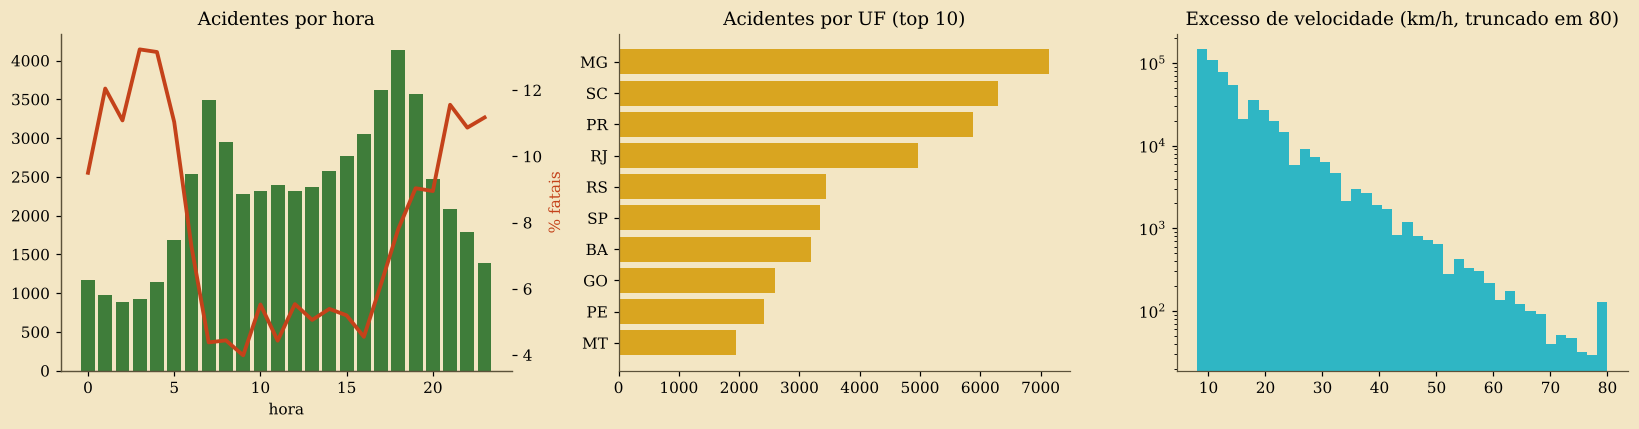

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
h = oc.dropna(subset=["hora"]).groupby("hora").agg(n=("id", "size"), fatal=("fatal", "mean"))
ax[0].bar(h.index, h["n"], color=P["moss"]); ax[0].set_title("Acidentes por hora"); ax[0].set_xlabel("hora")
ax2 = ax[0].twinx(); ax2.plot(h.index, 100 * h["fatal"], color=P["ember"], lw=2.5); ax2.set_ylabel("% fatais", color=P["ember"])
uf = oc["uf"].astype(str).value_counts().head(10)[::-1]
ax[1].barh(uf.index, uf.values, color=P["gold"]); ax[1].set_title("Acidentes por UF (top 10)")
ex = inf.loc[(inf.excesso_velocidade == 1) & (inf.excesso_verificado > 0), "excesso_verificado"]
ax[2].hist(ex.clip(upper=80), bins=40, color=P["sheikah"]); ax[2].set_title("Excesso de velocidade (km/h, truncado em 80)"); ax[2].set_yscale("log")
plt.tight_layout(); plt.show()

## 5. Correlações
Correlação de Spearman entre as contagens por ocorrência (robusta a assimetria) e entre infrações e acidentes por UF.

In [9]:
num = oc[["pessoas", "veiculos", "mortos", "feridos_leves", "feridos_graves", "ilesos", "hora", "km"]].astype(float)
num.corr(method="spearman").round(2)

,pessoas,veiculos,mortos,feridos_leves,feridos_graves,ilesos,hora,km
pessoas,1.00,0.71,0.13,0.23,0.13,0.62,0.04,0.02
veiculos,0.71,1.00,0.13,-0.01,0.08,0.51,0.04,0.00
mortos,0.13,0.13,1.00,-0.21,0.00,-0.05,0.02,0.03
feridos_leves,0.23,-0.01,-0.21,1.00,-0.36,-0.14,-0.01,-0.00
feridos_graves,0.13,0.08,0.00,-0.36,1.00,-0.09,0.03,0.00
ilesos,0.62,0.51,-0.05,-0.14,-0.09,1.00,0.03,-0.01
hora,0.04,0.04,0.02,-0.01,0.03,0.03,1.00,-0.01
km,0.02,0.00,0.03,-0.00,0.00,-0.01,-0.01,1.00


Período comum: julho de 2026
Spearman UF (acidentes × infrações): {'rho': 0.921, 'p': 0.0, 'n': 27}


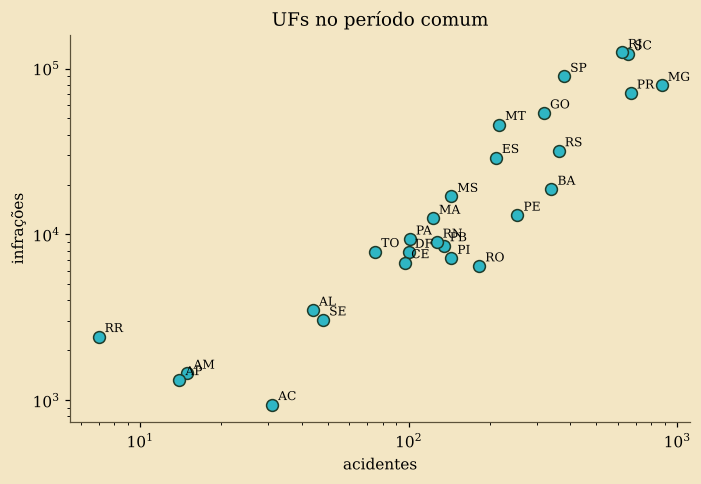

In [10]:
res, extra = an.run_analysis()
r3 = res["rq3"]
uf_df = pd.DataFrame(r3["uf"])
print("Período comum:", r3["periodo_comum"])
print("Spearman UF (acidentes × infrações):", {k: round(v, 3) for k, v in r3["corr_uf_acidentes"].items() if v is not None})
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(uf_df["acidentes"], uf_df["infracoes"], s=60, color=P["sheikah"], edgecolor=P["forest"])
for _, r in uf_df.iterrows(): ax.annotate(r["uf"], (r["acidentes"], r["infracoes"]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("acidentes"); ax.set_ylabel("infrações"); ax.set_title("UFs no período comum")
plt.tight_layout(); plt.show()

## 6. Principais achados da exploração

* **Qualidade:** poucos nulos nas ocorrências; em *pessoas*, os nulos de `idade`/`ano_fabricacao_veiculo` vêm de linhas sem pessoa/veículo e de sentinelas (0) tratadas pelo ETL.
* **Consistência:** a soma de óbitos por pessoa coincide com a soma por ocorrência.
* **Distribuições:** volume de acidentes é vespertino, enquanto a proporção de fatais sobe na madrugada; o excesso de velocidade tem cauda longa.
* **Associações:** infrações e acidentes por UF são fortemente correlacionados (escala), o que motiva a análise de *desvios* feita no artigo.
* **Próximo passo:** os testes formais (odds ratio, Mantel-Haenszel, Spearman) estão em `src/analysis.py` e discutidos no artigo.